## Google Colab setup

Set `REPO_URL`, `BRANCH`, `RUN_NAME` and `BASE` in the next cell. Open this notebook from the same GitHub branch. The setup mounts Drive, clones code into the runtime and installs dependencies; local execution skips it. Use a fresh runtime after pushing new code. All notebooks in one experiment use the same run name; choose a new name for a fresh experiment. Run preprocessing and feature engineering to completion before model notebooks. The repository README describes the dataset layout and execution order.


In [ ]:
# Configure this cell before running on Google Colab.
import os
import sys
import subprocess
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    REPO_URL = "https://github.com/YOUR_ACCOUNT/YOUR_REPOSITORY.git"
    BRANCH = "YOUR_BRANCH"
    RUN_NAME = "run_01"
    BASE = Path("/content/drive/MyDrive/BT4222")
    CHECKOUT = Path("/content/bt4222_checkout")
    drive.mount("/content/drive")
    if not CHECKOUT.exists():
        subprocess.run([
            "git", "clone", "--branch", BRANCH, "--single-branch",
            REPO_URL, str(CHECKOUT)
        ], check=True)
    active_branch = subprocess.check_output(
        ["git", "-C", str(CHECKOUT), "branch", "--show-current"], text=True
    ).strip()
    if active_branch != BRANCH:
        raise ValueError("Checkout branch differs from BRANCH. Use a fresh Colab runtime.")
    CODE_DIR = (CHECKOUT if (CHECKOUT / "utils/data_utils.py").is_file()
                else CHECKOUT / "bt4222-group12")
    if not (CODE_DIR / "utils/data_utils.py").is_file():
        raise FileNotFoundError("The selected branch does not contain the Group 12 project.")
    os.environ.update({
        "BT4222_BASE": str(BASE),
        "MIND_DATA_DIR": str(BASE / "data"),
        "BT4222_PROCESSED_DIR": str(BASE / "processed"),
        "BT4222_FEATURE_DIR": str(BASE / "features"),
        "BT4222_GLOVE_PATH": str(BASE / "data/glove/glove.6B.300d.txt"),
        "BT4222_OUTPUT_DIR": str(BASE / "runs" / RUN_NAME),
    })
    os.chdir(CODE_DIR)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-r", "requirements.txt"
    ], check=True)
    print("Code:", CODE_DIR)
    print("Features:", os.environ["BT4222_FEATURE_DIR"])
    print("Run outputs:", os.environ["BT4222_OUTPUT_DIR"])


# Exploratory Data Analysis

This analysis characterizes the logged MIND-small recommendation environment: who is observed, which articles are exposed, how clicks are distributed and how activity changes over time. The unit of analysis is stated for each result: user, impression, exposed candidate or article. A source-aware global impression ID prevents collisions between the original train and development files.

## Analytical scope

Read the preprocessed news and behavior tables. Expand each impression into candidates while retaining their order and labels. Report full-catalog statistics separately from exposure-level statistics. User-level history summaries use each user's earliest recorded impression; impression-level summaries retain the history supplied at each event.

For an article or group of exposures, empirical CTR is

$$\mathrm{CTR}=\frac{\sum_i y_i}{N_{exposures}}.$$

For history category proportions $p_c$, topical entropy is

$$H=-\sum_{c:p_c>0}p_c\log p_c.$$

Missing history represents an observed cold-user state, not an unknown timestamp. Inactivity is the elapsed time between consecutive recorded impressions, not between clicks. Zero gaps remain valid for the numeric summary. Article age uses first observed exposure as a proxy; it is not verified publication age.

## Reading the outputs

Slate/click distributions describe logging selection and competition within impressions. Exposure funnels distinguish a non-click from an unobserved article. Popularity concentration and history sparsity identify where collaborative signals are limited. Hourly/split comparisons describe observed temporal variation, not persistent weekly effects or causal benefits from rotation. Numeric, categorical and corpus tables are computed from the current data and exported alongside plots. Descriptive full-period CTR is not used as a historical training feature.


In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "utils" / "data_utils.py").is_file()
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.data_utils import project_paths, load_preprocessed, load_table, save_table

if os.environ.get("BT4222_USE_DRIVE") == "1":
    from google.colab import drive

    drive.mount("/content/drive")

PATHS = project_paths(PROJECT_ROOT)
from utils.data_utils import source_fingerprint, validate_features


In [2]:
import math
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIGURE_DIR = PATHS["outputs"] / "eda" / "figures"
TABLE_DIR = PATHS["outputs"] / "eda" / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
beh, news = load_preprocessed(PATHS)
print(beh.groupby("split").size())
print(news.isna().sum())


split
test      73152
train    126695
val       30270
dtype: int64
news_id                 0
category                0
subcategory             0
title                   0
abstract             3415
url                     0
title_entities          0
abstract_entities       0
dtype: int64


## 1. Impressions and exposed candidates


In [3]:
exposures = beh[["impression_id", "user_id", "time", "impressions"]].copy()
exposures["candidate"] = exposures["impressions"].str.split()
exposures = exposures.explode("candidate", ignore_index=True)
exposures[["news_id", "label"]] = exposures["candidate"].str.rsplit(
    "-", n=1, expand=True
)
exposures["label"] = exposures["label"].astype(np.int8)
exposures["position"] = exposures.groupby("impression_id").cumcount() + 1
exposures = exposures.drop(columns=["impressions", "candidate"])
print(
    f"Users: {beh.user_id.nunique():,}; impressions: {len(beh):,}; exposures: {len(exposures):,}"
)


Users: 94,057; impressions: 230,117; exposures: 8,584,442


In [4]:
print("Article exposure records:", len(exposures))
print("Unique clicked values:", exposures["label"].unique())
exposures.head()


Article exposure records: 8584442
Unique clicked values: [0 1]


,impression_id,user_id,time,news_id,label,position
0,1,U65916,2019-11-09 00:00:19,N54300,0,1
1,1,U65916,2019-11-09 00:00:19,N46057,1,2
2,1,U65916,2019-11-09 00:00:19,N57005,0,3
3,1,U65916,2019-11-09 00:00:19,N52154,0,4
4,1,U65916,2019-11-09 00:00:19,N57099,0,5


In [5]:
slate_summary = (
    exposures.groupby("impression_id")
    .agg(slate_length=("news_id", "size"), clicks=("label", "sum"))
    .reset_index()
)
exposures["slate_length"] = (
    exposures["impression_id"]
    .map(slate_summary.set_index("impression_id")["slate_length"])
    .astype("int16")
)


In [6]:
print("Impressions:", len(slate_summary))
slate_summary[["slate_length"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)


Impressions: 230117


,slate_length
count,230117.000000
mean,37.304684
std,38.897923
min,2.000000
5%,2.000000
25%,10.000000
50%,24.000000
75%,51.000000
90%,92.000000
95%,118.000000


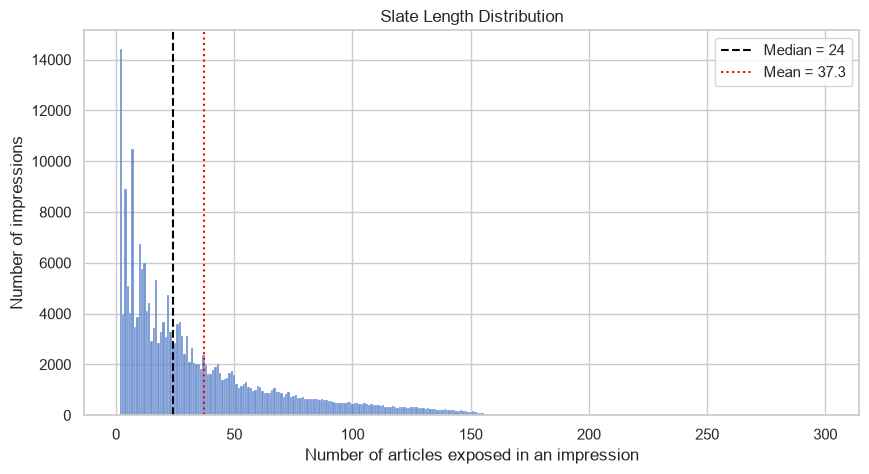

In [7]:
mean_len = slate_summary["slate_length"].mean()
median_len = slate_summary["slate_length"].median()
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    data=slate_summary, x="slate_length", discrete=True, color="#4472C4", ax=ax
)
ax.set_title(f"Slate Length Distribution")
ax.axvline(
    median_len, color="black", linestyle="--", label=f"Median = {median_len:.0f}"
)
ax.axvline(mean_len, color="red", linestyle=":", label=f"Mean = {mean_len:.1f}")
ax.set_xlabel("Number of articles exposed in an impression")
ax.set_ylabel("Number of impressions")
ax.legend()
plt.show()


In [8]:
click_summary = (
    slate_summary["clicks"]
    .value_counts()
    .sort_index()
    .rename_axis("clicks")
    .reset_index(name="number_of_impressions")
)
click_summary["percentage"] = (
    click_summary["number_of_impressions"]
    / click_summary["number_of_impressions"].sum()
    * 100
)
click_summary["percentage"] = click_summary["percentage"].round(2)
click_summary


,clicks,number_of_impressions,percentage
0,1,165955,72.12
1,2,38278,16.63
2,3,13706,5.96
3,4,5886,2.56
4,5,2889,1.26
5,6,1368,0.59
6,7,783,0.34
7,8,462,0.20
8,9,281,0.12
9,10,178,0.08


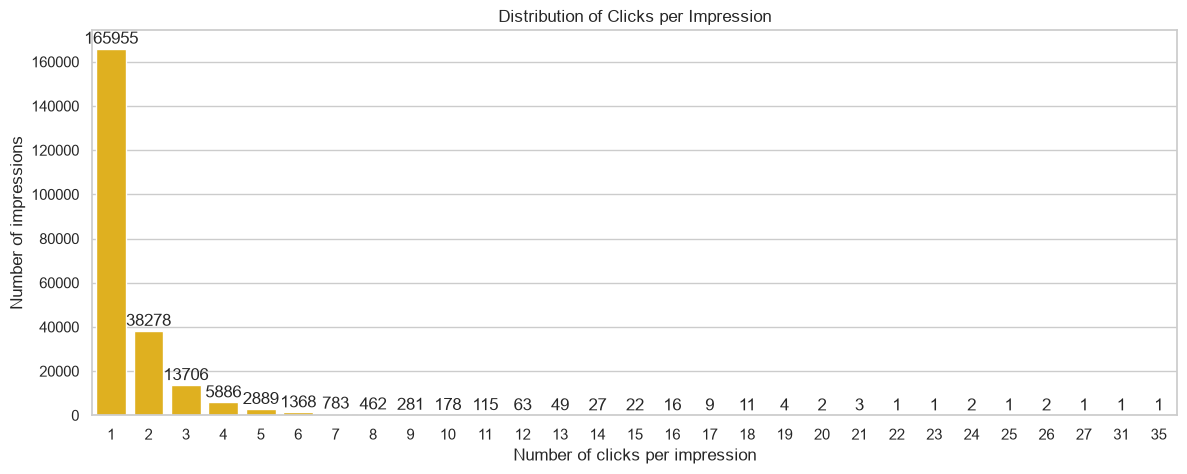

In [9]:
plt.figure(figsize=(14, 5))
ax = sns.barplot(
    data=click_summary, x="clicks", y="number_of_impressions", color="#FFC000"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=1)

plt.xlabel("Number of clicks per impression")
plt.ylabel("Number of impressions")
plt.title("Distribution of Clicks per Impression")
plt.show()


In [10]:
print("Impressions with no click:", (slate_summary["clicks"] == 0).sum())


Impressions with no click: 0


In [11]:
print("Clicked exposures:", exposures["label"].sum())
print("Unclicked exposures:", (exposures["label"] == 0).sum())
print("Exposure-level CTR:", exposures["label"].mean())


Clicked exposures: 347727
Unclicked exposures: 8236715
Exposure-level CTR: 0.04050665145154455


In [12]:
slate_length_summary = (
    slate_summary.groupby("slate_length")
    .agg(impressions=("impression_id", "size"), total_clicks=("clicks", "sum"))
    .reset_index()
)
slate_length_summary["exposures"] = (
    slate_length_summary["slate_length"] * slate_length_summary["impressions"]
)
slate_length_summary["exposure_level_ctr"] = (
    slate_length_summary["total_clicks"] / slate_length_summary["exposures"]
)
slate_length_summary["min_ctr"] = 1 / slate_length_summary["slate_length"]
slate_length_summary["excess_over_min"] = (
    slate_length_summary["exposure_level_ctr"] - slate_length_summary["min_ctr"]
)
pd.concat([slate_length_summary.head(5), slate_length_summary.tail(5)])


,slate_length,impressions,total_clicks,exposures,exposure_level_ctr,min_ctr,excess_over_min
0,2,14434,14434,28868,0.500000,0.500000,0.000000
1,3,3989,4037,11967,0.337344,0.333333,0.004011
2,4,8898,9167,35592,0.257558,0.250000,0.007558
3,5,5080,5259,25400,0.207047,0.200000,0.007047
4,6,4036,4301,24216,0.177610,0.166667,0.010943
291,293,2,4,586,0.006826,0.003413,0.003413
292,294,4,8,1176,0.006803,0.003401,0.003401
293,295,4,9,1180,0.007627,0.003390,0.004237
294,297,1,1,297,0.003367,0.003367,0.000000
295,299,1,2,299,0.006689,0.003344,0.003344


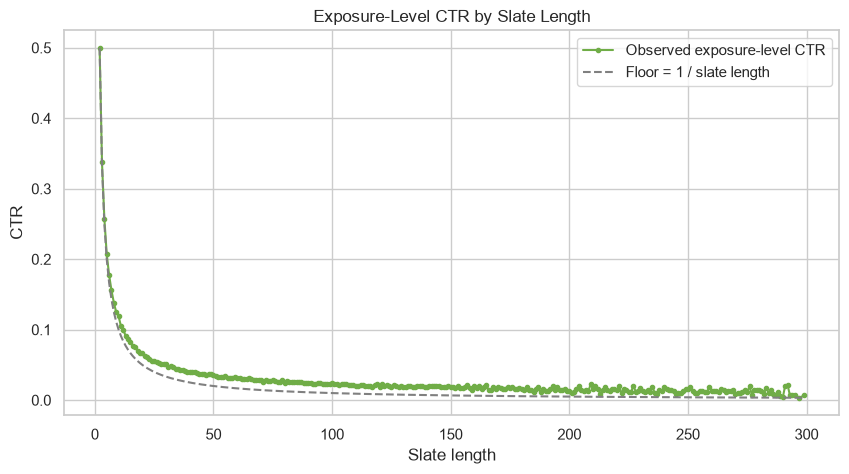

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    slate_length_summary["slate_length"],
    slate_length_summary["exposure_level_ctr"],
    marker="o",
    markersize=3,
    color="#70AD47",
    label="Observed exposure-level CTR",
)
ax.plot(
    slate_length_summary["slate_length"],
    slate_length_summary["min_ctr"],
    linestyle="--",
    color="grey",
    label="Floor = 1 / slate length",
)
ax.set_title(f"Exposure-Level CTR by Slate Length")
ax.set_xlabel("Slate length")
ax.set_ylabel("CTR")
ax.legend()
plt.show()


## 2. Interaction hierarchy and feedback semantics


In [14]:
print("Unique labels:", sorted(exposures["label"].unique()))
print("Missing values:")
display(exposures.isna().sum())
print("Unique impressions before expansion:", beh["impression_id"].nunique())
print("Unique impressions after expansion:", exposures["impression_id"].nunique())
print(
    "Duplicate impression-article pairs:",
    exposures.duplicated(["impression_id", "news_id"]).sum(),
)


Unique labels: [np.int8(0), np.int8(1)]
Missing values:


impression_id    0
user_id          0
time             0
news_id          0
label            0
position         0
slate_length     0
dtype: int64

Unique impressions before expansion: 230117
Unique impressions after expansion: 230117
Duplicate impression-article pairs: 0


In [15]:
impression_summary = (
    exposures.groupby("impression_id")
    .agg(
        user_id=("user_id", "first"),
        time=("time", "first"),
        slate_length=("news_id", "size"),
        click_count=("label", "sum"),
    )
    .reset_index()
)
impression_summary["non_click_count"] = (
    impression_summary["slate_length"] - impression_summary["click_count"]
)
impression_summary["impression_ctr"] = (
    impression_summary["click_count"] / impression_summary["slate_length"]
)
display(impression_summary.head())


,impression_id,user_id,time,slate_length,click_count,non_click_count,impression_ctr
0,1,U65916,2019-11-09 00:00:19,31,3,28,0.096774
1,2,U49985,2019-11-09 00:01:13,29,5,24,0.172414
2,3,U25550,2019-11-09 00:02:44,5,1,4,0.200000
3,4,U19710,2019-11-09 00:02:50,56,1,55,0.017857
4,5,U38106,2019-11-09 00:03:09,48,1,47,0.020833


In [16]:
FIGURE_DIR = PATHS["outputs"] / "eda" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


## 3. Interaction Hierarchy and Funnel

MIND records article exposures and binary click outcomes but does not provide
downstream interaction stages such as reading duration, sharing or subscription.
The observable item-level funnel is therefore limited to exposure and click.


In [17]:
total_impressions = len(impression_summary)
total_exposures = len(exposures)
total_clicks = exposures["label"].sum()
total_non_clicks = total_exposures - total_clicks
overall_ctr = total_clicks / total_exposures
zero_click_impressions = impression_summary["click_count"].eq(0).sum()
one_click_impressions = impression_summary["click_count"].eq(1).sum()
multiple_click_impressions = impression_summary["click_count"].gt(1).sum()
interaction_statistics = pd.Series(
    {
        "Total impressions": total_impressions,
        "Total article exposures": total_exposures,
        "Total clicked exposures": total_clicks,
        "Total unclicked exposures": total_non_clicks,
        "Overall item-level CTR": overall_ctr,
        "Mean slate length": impression_summary["slate_length"].mean(),
        "Median slate length": impression_summary["slate_length"].median(),
        "Minimum slate length": impression_summary["slate_length"].min(),
        "Maximum slate length": impression_summary["slate_length"].max(),
        "Zero-click impressions": zero_click_impressions,
        "One-click impressions": one_click_impressions,
        "Multiple-click impressions": multiple_click_impressions,
    }
)
display(interaction_statistics)


Total impressions             2.301170e+05
Total article exposures       8.584442e+06
Total clicked exposures       3.477270e+05
Total unclicked exposures     8.236715e+06
Overall item-level CTR        4.050665e-02
Mean slate length             3.730468e+01
Median slate length           2.400000e+01
Minimum slate length          2.000000e+00
Maximum slate length          2.990000e+02
Zero-click impressions        0.000000e+00
One-click impressions         1.659550e+05
Multiple-click impressions    6.416200e+04
dtype: float64

In [18]:
impression_click_rate = impression_summary["click_count"].gt(0).mean()
print(f"Overall item-level CTR: {overall_ctr:.4f}")
print(f"Impression-level click rate: {impression_click_rate:.4f}")


Overall item-level CTR: 0.0405
Impression-level click rate: 1.0000


In [19]:
funnel_summary = pd.DataFrame(
    {
        "Stage": ["Article exposures", "Clicked exposures"],
        "Count": [total_exposures, total_clicks],
        "Percentage of exposures": [100, overall_ctr * 100],
    }
)
display(funnel_summary)


,Stage,Count,Percentage of exposures
0,Article exposures,8584442,100.000000
1,Clicked exposures,347727,4.050665


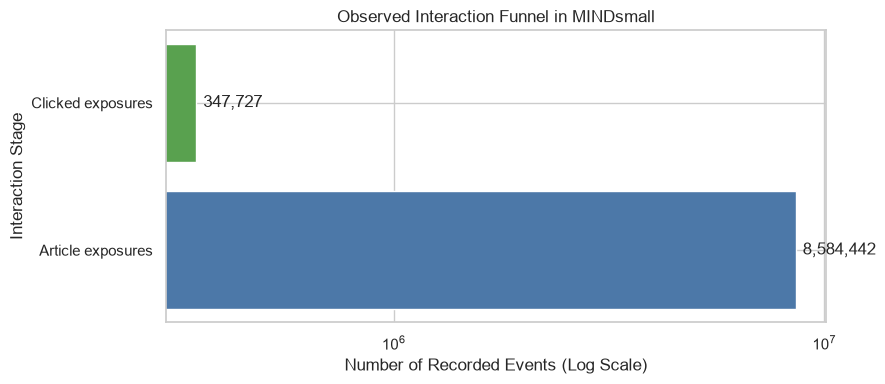

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(
    funnel_summary["Stage"], funnel_summary["Count"], color=["#4C78A8", "#59A14F"]
)
ax.set_xscale("log")
ax.set_title("Observed Interaction Funnel in MINDsmall")
ax.set_xlabel("Number of Recorded Events (Log Scale)")
ax.set_ylabel("Interaction Stage")
ax.bar_label(
    bars, labels=[f"{count:,}" for count in funnel_summary["Count"]], padding=5
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "interaction_funnel.png", dpi=300, bbox_inches="tight")
plt.show()


The funnel counts article exposures and clicked exposures. The item-level conversion rate is clicks divided by exposures; the impression-level click rate measures slates with at least one click. These have different denominators. The observed slate click rate reflects the supplied dataset and should not be interpreted as platform-wide engagement. No post-click conversion can be measured from these logs.


## 4. Feedback Semantics

MIND distinguishes between clicked articles, exposed-but-unclicked articles and
articles for which no user-specific exposure was recorded. These feedback states
should not be interpreted as equally strong preference signals.


| State | Recorded label | Interpretation |
|---|---|---|
| Exposed and clicked | 1 | Observed positive implicit feedback |
| Exposed but unclicked | 0 | Observed non-click; a potentially noisy negative training signal |
| No recorded exposure for this user–article pair | None | Unobserved feedback, not a zero label or evidence of dislike |

A non-click is explicitly recorded in the exposure log, but it is not an explicit dislike rating. An article absent from an impression must not automatically be assigned label 0. No recorded exposure does not prove the user never saw the article outside these logs.


In [21]:
feedback_summary = pd.DataFrame(
    {
        "Feedback type": ["Clicked", "Exposed but unclicked"],
        "Label": [1, 0],
        "Count": [total_clicks, total_non_clicks],
        "Percentage": [
            total_clicks / total_exposures * 100,
            total_non_clicks / total_exposures * 100,
        ],
    }
)
display(feedback_summary)


,Feedback type,Label,Count,Percentage
0,Clicked,1,347727,4.050665
1,Exposed but unclicked,0,8236715,95.949335


In [22]:
user_article_feedback = (
    exposures.groupby(["user_id", "news_id"])
    .agg(
        exposure_count=("label", "size"),
        click_count=("label", "sum"),
        different_labels=("label", "nunique"),
    )
    .reset_index()
)
repeated_pairs = user_article_feedback[user_article_feedback["exposure_count"] > 1]
mixed_feedback_pairs = user_article_feedback[
    user_article_feedback["different_labels"] > 1
]
feedback_consistency = pd.Series(
    {
        "Unique exposed user-article pairs": len(user_article_feedback),
        "Pairs exposed more than once": len(repeated_pairs),
        "Pairs observed with both labels": len(mixed_feedback_pairs),
        "Mixed-label percentage among repeated pairs": (
            len(mixed_feedback_pairs) / len(repeated_pairs) * 100
            if len(repeated_pairs) > 0
            else 0
        ),
    }
)
display(feedback_consistency)


Unique exposed user-article pairs              7.437956e+06
Pairs exposed more than once                   8.903870e+05
Pairs observed with both labels                6.282800e+04
Mixed-label percentage among repeated pairs    7.056258e+00
dtype: float64

In [23]:
clicked_pct = feedback_summary.loc[
    feedback_summary["Feedback type"] == "Clicked", "Percentage"
].iloc[0]
unclicked_pct = 100 - clicked_pct
mixed_pct = len(mixed_feedback_pairs) / len(repeated_pairs) * 100
consistent_pct = 100 - mixed_pct
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
bar_height = 0.45
axes[0].barh(0, clicked_pct, height=bar_height, color="#E76F51", edgecolor="white")
axes[0].barh(
    0,
    unclicked_pct,
    left=clicked_pct,
    height=bar_height,
    color="#4C86A8",
    edgecolor="white",
)
axes[0].annotate(
    f"Clicked\n{clicked_pct:.2f}%",
    xy=(clicked_pct / 2, bar_height / 2),
    xytext=(7, 0.48),
    ha="center",
    va="bottom",
    color="#C94F33",
    fontweight="bold",
    arrowprops=dict(arrowstyle="-", color="#C94F33", linewidth=1),
)
axes[0].text(
    clicked_pct + unclicked_pct / 2,
    0,
    f"Exposed but unclicked\n{unclicked_pct:.2f}%",
    ha="center",
    va="center",
    color="white",
    fontweight="bold",
)
axes[0].set_title(
    "A. Distribution of Exposure-Level Feedback", pad=16, fontweight="bold"
)
axes[0].set_yticks([])
axes[1].barh(0, mixed_pct, height=bar_height, color="#F4A261", edgecolor="white")


<BarContainer object of 1 artists>

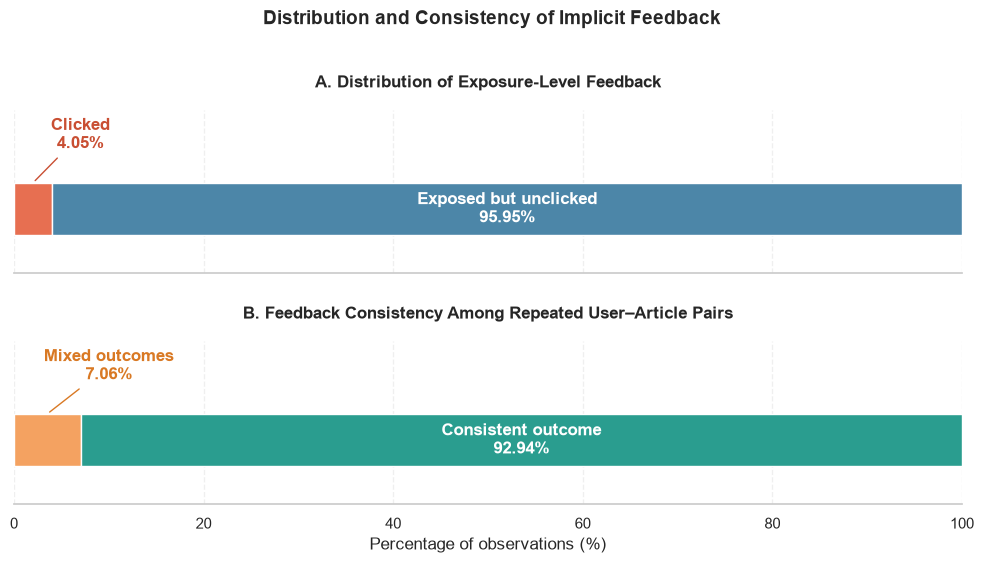

In [24]:
axes[1].barh(
    0,
    consistent_pct,
    left=mixed_pct,
    height=bar_height,
    color="#2A9D8F",
    edgecolor="white",
)
axes[1].annotate(
    f"Mixed outcomes\n{mixed_pct:.2f}%",
    xy=(mixed_pct / 2, bar_height / 2),
    xytext=(10, 0.48),
    ha="center",
    va="bottom",
    color="#D97924",
    fontweight="bold",
    arrowprops=dict(arrowstyle="-", color="#D97924", linewidth=1),
)
axes[1].text(
    mixed_pct + consistent_pct / 2,
    0,
    f"Consistent outcome\n{consistent_pct:.2f}%",
    ha="center",
    va="center",
    color="white",
    fontweight="bold",
)
axes[1].set_title(
    "B. Feedback Consistency Among Repeated User–Article Pairs",
    pad=16,
    fontweight="bold",
)
axes[1].set_yticks([])
axes[1].set_xlabel("Percentage of observations (%)")

for ax in axes:
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.55, 0.85)
    ax.set_xticks(range(0, 101, 20))
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

fig.suptitle(
    "Distribution and Consistency of Implicit Feedback",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout(h_pad=2.0)
plt.savefig(FIGURE_DIR / "feedback_semantics.png", dpi=300, bbox_inches="tight")
plt.show()


Repeated user–article pairs can receive both labels across impressions. This shows that a non-click need not indicate a stable dislike: context and competing articles may affect the outcome. The table above reports the counts and mixed-outcome rate for the combined logs.


## 5. Sparsity, popularity and temporal patterns


In [25]:
imp = beh["impressions"].str.split().explode()
ex = pd.DataFrame(
    {"news_id": imp.str[:-2].values, "label": imp.str[-1].astype("int8").values}
)
item = ex.groupby("news_id")["label"].agg(clicks="sum", exposures="size")
N_USERS = beh["user_id"].nunique()
N_ITEMS = len(item)
N_CLICKS = int(item["clicks"].sum())
DENSITY = N_CLICKS / (N_USERS * N_ITEMS) * 100
imp_per_user = beh.groupby("user_id").size()
print(f"users {N_USERS:,} | articles {N_ITEMS:,} | clicks {N_CLICKS:,}")
print(
    f"news catalogue {len(news):,} | exposed articles found in catalogue {item.index.isin(news['news_id']).mean()*100:.1f}%"
)


users 94,057 | articles 22,771 | clicks 347,727
news catalogue 65,238 | exposed articles found in catalogue 100.0%


## 6. User sparsity: click-history length (report Fig. 8)
Each user's history length is the number of article IDs in their `history` field; we take the maximum across that user's impressions (history only grows over time). The histogram is clipped at 100 for readability, so the bar at 100 holds all users with ≥100 clicks.

**Why it matters:** 17.9% of users have fewer than 5 historical clicks and 2.3% have none, so user-ID embeddings would be learned from very little data. This motivates content- and time-based features that are shared across users.


count    94057.000000
mean        21.663778
std         27.783628
min          0.000000
25%          6.000000
50%         12.000000
75%         26.000000
max        558.000000
Name: hist_len, dtype: float64
0 history 2.26% | <5 17.91% | >100 2.36%


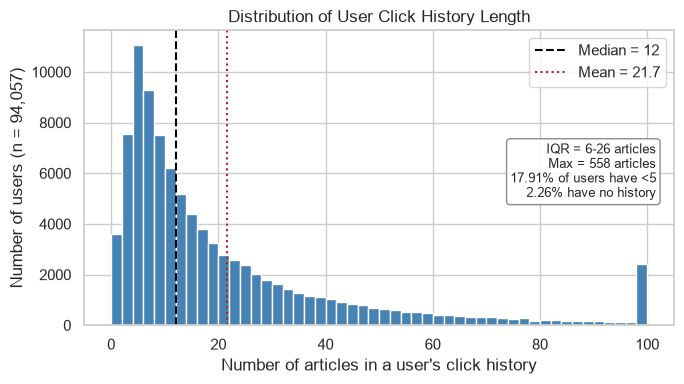

In [26]:
beh["hist_len"] = beh["history"].str.split().str.len().fillna(0).astype(int)
hist_len = (
    beh.sort_values(["time", "impression_id"])
    .drop_duplicates("user_id")
    .set_index("user_id")["hist_len"]
)
med, mean = hist_len.median(), hist_len.mean()
q1, q3 = hist_len.quantile(0.25), hist_len.quantile(0.75)
pct0, pct5 = (hist_len == 0).mean() * 100, (hist_len < 5).mean() * 100
XMAX = 100
print(hist_len.describe())
print(
    f"0 history {pct0:.2f}% | <5 {pct5:.2f}% | >100 {(hist_len>XMAX).mean()*100:.2f}%"
)
plt.figure(figsize=(7, 4))
plt.hist(hist_len.clip(upper=XMAX), bins=np.arange(0, XMAX + 2, 2), color="steelblue")
plt.axvline(med, color="black", ls="--", label=f"Median = {med:.0f}")
plt.axvline(mean, color="firebrick", ls=":", label=f"Mean = {mean:.1f}")
plt.text(
    0.97,
    0.62,
    f"IQR = {q1:.0f}-{q3:.0f} articles\n"
    f"Max = {hist_len.max():.0f} articles\n"
    f"{pct5:.2f}% of users have <5\n"
    f"{pct0:.2f}% have no history",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9),
)
plt.xlabel("Number of articles in a user's click history")
plt.ylabel(f"Number of users (n = {N_USERS:,})")
plt.title("Distribution of User Click History Length")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 7. Article popularity concentration (report Fig. 9)
Articles are ranked from most to least clicked, and the cumulative share of clicks is plotted against the share of articles. `share(f)` returns the share of all clicks captured by the top *f*% of articles.

**Why it matters:** 60% of exposed articles are never clicked and the top 1% take 54% of clicks, so a popularity baseline is strong but cannot rank fresh, unclicked articles. This motivates pairing `historical_ctr` with recency.


never clicked 60.0% | top1 54.3% top5 84.6% top20 98.3%


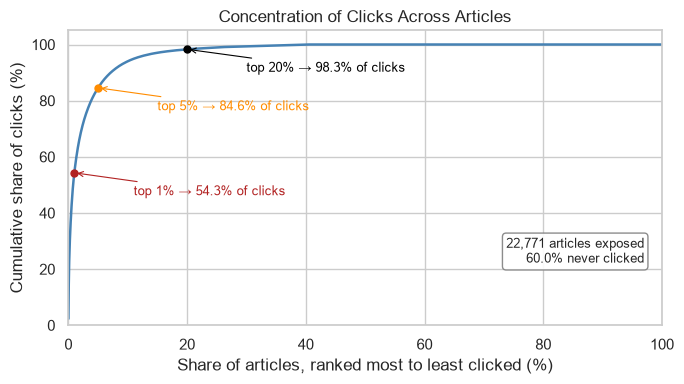

In [27]:
c = item["clicks"].sort_values(ascending=False).to_numpy()
x = np.arange(1, len(c) + 1) / len(c) * 100
y = np.cumsum(c) / c.sum() * 100


def share(f):
    k = max(1, int(round(f / 100 * len(c))))
    return c[:k].sum() / c.sum() * 100


zero = (c == 0).mean() * 100
print(
    f"never clicked {zero:.1f}% | top1 {share(1):.1f}% top5 {share(5):.1f}% top20 {share(20):.1f}%"
)
plt.figure(figsize=(7, 4))
plt.plot(x, y, color="steelblue", lw=1.8)

for f, col in [(1, "firebrick"), (5, "darkorange"), (20, "black")]:
    s = share(f)
    plt.plot([f], [s], "o", color=col, ms=5)
    plt.annotate(
        f"top {f}% → {s:.1f}% of clicks",
        xy=(f, s),
        xytext=(f + 10, s - 8),
        fontsize=9,
        color=col,
        arrowprops=dict(arrowstyle="->", color=col, lw=0.8),
    )

plt.text(
    0.97,
    0.30,
    f"{len(c):,} articles exposed\n{zero:.1f}% never clicked",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9),
)
plt.xlim(0, 100)
plt.ylim(0, 105)
plt.xlabel("Share of articles, ranked most to least clicked (%)")
plt.ylabel("Cumulative share of clicks (%)")
plt.title("Concentration of Clicks Across Articles")
plt.tight_layout()
plt.show()


## 8. Time gaps between a user's consecutive impressions (report Fig. 11)
Impressions are sorted by user and time; the gap is the difference between consecutive timestamps for the same user (each user's first impression has no gap and is dropped, zero gaps are retained). The histogram covers 0–72 h, with reference lines at 24 h and 48 h.

**Why it matters:** the distribution is multi-modal (same-session returns, then bumps at ~24 h and ~48 h), so the median of 7.2 h is not a typical gap. This motivates binning `inactivity_gap` rather than using a single average.


gaps 136,060 | median 7.2 h | <30min 11.3% | 20-28h 16.3% | 44-52h 5.3% | >72h 3.1%
window: 2019-11-09 00:00:19 to 2019-11-15 23:58:03


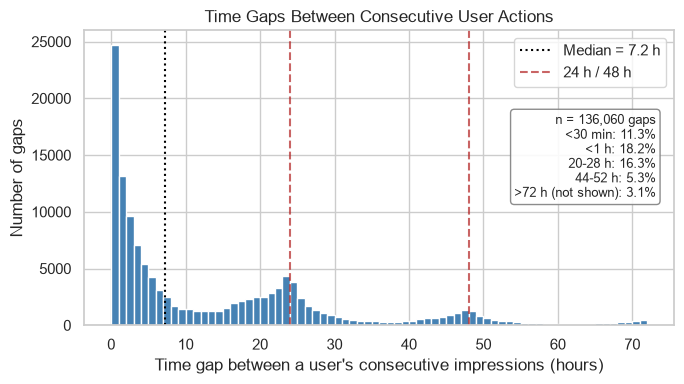

In [28]:
g = (
    beh.sort_values(["user_id", "time"])
    .groupby("user_id")["time"]
    .diff()
    .dt.total_seconds()
    / 60
)
g = g.dropna()
g = g[g >= 0]
gh = g / 60


def band(a, b):
    return ((gh >= a) & (gh <= b)).mean() * 100


p1, p24, p48 = (gh < 1).mean() * 100, band(20, 28), band(44, 52)
beyond = (gh > 72).mean() * 100
print(
    f"gaps {len(gh):,} | median {gh.median():.1f} h | <30min {(gh<0.5).mean()*100:.1f}% "
    f"| 20-28h {p24:.1f}% | 44-52h {p48:.1f}% | >72h {beyond:.1f}%"
)
print(f"window: {beh.time.min()} to {beh.time.max()}")
plt.figure(figsize=(7, 4))
plt.hist(gh[gh <= 72], bins=72, color="steelblue")

for h in (24, 48):
    plt.axvline(h, color="firebrick", ls="--", alpha=0.7)

plt.axvline(gh.median(), color="black", ls=":", label=f"Median = {gh.median():.1f} h")
plt.plot([], [], color="firebrick", ls="--", alpha=0.7, label="24 h / 48 h")
plt.text(
    0.97,
    0.72,
    f"n = {len(gh):,} gaps\n"
    f"<30 min: {(gh<0.5).mean()*100:.1f}%\n"
    f"<1 h: {p1:.1f}%\n"
    f"20-28 h: {p24:.1f}%\n"
    f"44-52 h: {p48:.1f}%\n"
    f">72 h (not shown): {beyond:.1f}%",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9),
)
plt.xlabel("Time gap between a user's consecutive impressions (hours)")
plt.ylabel("Number of gaps")
plt.title("Time Gaps Between Consecutive User Actions")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 9. Clicks by hour of day (report Fig. 10)
Each exposure inherits the hour of its impression (`repeat` by slate length keeps rows aligned with `ex`, checked by the `assert`), then clicks are summed per hour.

**Why it matters:** clicks peak at 08:00 and are lowest around 23:00, so the value of a Spotlight slot depends on when it is filled. This supports `session_hour` as a feature and time-window based slate rotation.


hour
0      2364
1      2772
2      4312
3      7574
4     13177
5     20966
6     25904
7     27182
8     29277
9     25962
10    28097
11    28210
12    26160
13    23547
14    18461
15    14000
16    11689
17     9290
18     7750
19     6253
20     5202
21     4230
22     3108
23     2240
Name: label, dtype: int64
peak 08:00 (29,277) | quietest 23:00 (2,240) 


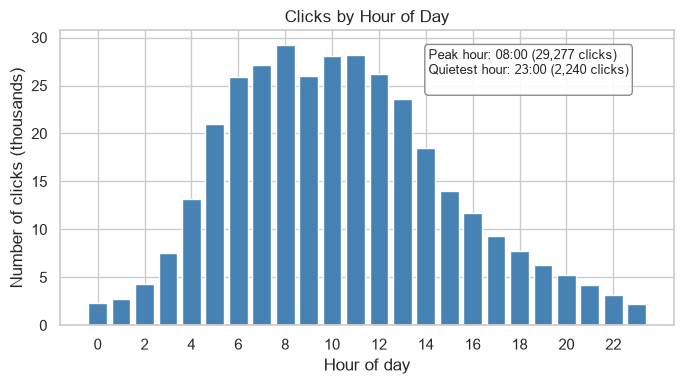

In [29]:
slate_len = beh["impressions"].str.split().str.len()
hr = pd.DataFrame(
    {"hour": beh["time"].dt.hour.repeat(slate_len).values, "label": ex["label"].values}
)
assert len(hr) == len(ex)
hourly = hr.groupby("hour")["label"].sum()
peak, low = hourly.idxmax(), hourly.idxmin()
print(hourly)
print(
    f"peak {peak:02d}:00 ({hourly.max():,}) | quietest {low:02d}:00 ({hourly.min():,}) "
)
plt.figure(figsize=(7, 4))
plt.bar(hourly.index, hourly / 1000, color="steelblue")
plt.xticks(range(0, 24, 2))
plt.text(
    0.60,
    0.94,
    f"Peak hour: {peak:02d}:00 ({hourly.max():,} clicks)\n"
    f"Quietest hour: {low:02d}:00 ({hourly.min():,} clicks)\n",
    transform=plt.gca().transAxes,
    ha="left",
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9),
)
plt.xlabel("Hour of day")
plt.ylabel("Number of clicks (thousands)")
plt.title("Clicks by Hour of Day")
plt.tight_layout()
plt.show()


## 10. Content and context distributions


In [30]:
import json
from utils.data_utils import source_directory

beh, news = load_preprocessed(PATHS)
categories = sorted(news["category"].unique())
cat2id = {c: i for i, c in enumerate(categories)}
news["category_id"] = news["category"].map(cat2id)
subcategories = sorted(news["subcategory"].unique())
subcat2id = {s: i for i, s in enumerate(subcategories)}
news["subcategory_id"] = news["subcategory"].map(subcat2id)
news_cat_map = dict(zip(news["news_id"], news["category"]))
news["title_word_count"] = news["title"].fillna("").apply(lambda x: len(x.split()))
news["title_char_length"] = news["title"].fillna("").apply(len)
abs_valid = news["abstract"].dropna()
abs_word_count = abs_valid.apply(lambda x: len(x.split()))
abs_char_length = abs_valid.apply(len)
missing_abstracts = news["abstract"].isna().sum()
news["abstract_imputed"] = news["abstract"].fillna(news["title"])
print(f"Categories (category_id):         {len(categories)} classes")
print(f"Subcategories (subcategory_id):   {len(subcategories)} classes")
print(
    f"Articles with Missing Abstract:   {missing_abstracts:,} ({missing_abstracts / len(news) * 100:.2f}%) -> Imputed with title"
)


def parse_entities(x):
    if not isinstance(x, str) or not x.strip():
        return []
    try:
        return json.loads(x)
    except (ValueError, TypeError):
        return []


news["title_ents"] = news["title_entities"].apply(parse_entities)
news["abs_ents"] = news["abstract_entities"].apply(parse_entities)
news["title_kg_count"] = news["title_ents"].apply(len)
news["abs_kg_count"] = news["abs_ents"].apply(len)
news["total_kg_count"] = news["title_kg_count"] + news["abs_kg_count"]
articles_with_kg = (news["total_kg_count"] > 0).sum()
articles_without_kg = (news["total_kg_count"] == 0).sum()
print(
    f"Articles with >= 1 KG entity:     {articles_with_kg:,} ({articles_with_kg / len(news) * 100:.2f}%)"
)
print(
    f"Articles without KG entity:       {articles_without_kg:,} ({articles_without_kg / len(news) * 100:.2f}%) -> Zero vector in R^100"
)
kg_embedding_file = source_directory(PATHS["raw"], "train") / "entity_embedding.vec"
entity_embs = {}

with open(kg_embedding_file) as f:
    for line in f:
        parts = line.strip().split("\t")
        if len(parts) >= 101:
            entity_embs[parts[0]] = np.array(parts[1:101], dtype=np.float32)

print(f"Loaded Precomputed TransE Entities: {len(entity_embs):,} vectors (100-dim)")
kg_entity_matrix = np.zeros((len(news), 100), dtype=np.float32)

for idx, (t_ents, a_ents) in enumerate(zip(news["title_ents"], news["abs_ents"])):
    all_qids = [
        e.get("WikidataId")
        for e in t_ents + a_ents
        if e.get("WikidataId") in entity_embs
    ]
    if all_qids:
        vecs = [entity_embs[qid] for qid in all_qids]
        kg_entity_matrix[idx] = np.mean(vecs, axis=0)

print(f"Generated kg_entity_emb matrix shape: {kg_entity_matrix.shape}")
beh["datetime"] = pd.to_datetime(beh["time"], format="%m/%d/%Y %I:%M:%S %p")
cand_clicks = defaultdict(int)
cand_exposures = defaultdict(int)
first_seen = {}


Categories (category_id):         18 classes
Subcategories (subcategory_id):   270 classes
Articles with Missing Abstract:   3,415 (5.23%) -> Imputed with title
Articles with >= 1 KG entity:     57,054 (87.46%)
Articles without KG entity:       8,184 (12.54%) -> Zero vector in R^100
Loaded Precomputed TransE Entities: 26,904 vectors (100-dim)
Generated kg_entity_emb matrix shape: (65238, 100)


In [31]:
for dt, impr in zip(beh["datetime"], beh["impressions"]):
    for item in impr.split():
        nid, lbl = item.split("-")
        cand_exposures[nid] += 1
        if lbl == "1":
            cand_clicks[nid] += 1
        if nid not in first_seen or dt < first_seen[nid]:
            first_seen[nid] = dt

cand_ctrs = pd.Series(
    [cand_clicks[nid] / cand_exposures[nid] for nid in cand_exposures]
)
print(f"Candidate Articles Evaluated for CTR: {len(cand_ctrs):,}")
print(
    f"historical_ctr: Mean = {cand_ctrs.mean():.4f} ± {cand_ctrs.std():.4f} | Median = {cand_ctrs.median():.4f} | Range = [{cand_ctrs.min():.2f}, {cand_ctrs.max():.2f}]"
)
sample_rows = beh.sample(n=min(10000, len(beh)), random_state=42)
recency_sample = []

for dt, impr in zip(sample_rows["datetime"], sample_rows["impressions"]):
    for item in impr.split():
        nid = item.split("-")[0]
        rec = (dt - first_seen[nid]).total_seconds() / 3600.0
        recency_sample.append(rec)
        if len(recency_sample) >= 200000:
            break
    if len(recency_sample) >= 200000:
        break

recency_series = pd.Series(recency_sample[:200000])
print(
    f"article_recency (N={len(recency_series):,}): Mean = {recency_series.mean():.2f}h ± {recency_series.std():.2f}h | Median = {recency_series.median():.2f}h [{recency_series.quantile(0.25):.2f}h, {recency_series.quantile(0.75):.2f}h]"
)
unique_users = beh.drop_duplicates(subset=["user_id"]).copy()
unique_users["history_length"] = unique_users["history"].apply(
    lambda x: len(x.split()) if isinstance(x, str) and str(x) != "nan" else 0
)
unique_users["has_history"] = (unique_users["history_length"] > 0).astype(int)
beh["history_length"] = beh["history"].apply(
    lambda x: len(x.split()) if isinstance(x, str) and str(x) != "nan" else 0
)
beh["has_history"] = (beh["history_length"] > 0).astype(int)
user_entropies = {}
user_top_cat = {}
user_affinities = {}

for uid, hist in zip(unique_users["user_id"], unique_users["history"]):
    if not isinstance(hist, str) or not hist.strip() or str(hist) == "nan":
        continue
    nids = hist.split()
    cats = [news_cat_map[nid] for nid in nids if nid in news_cat_map]
    if not cats:
        continue
    counts = Counter(cats)
    tot = len(cats)
    ent = -sum((cnt / tot * math.log(cnt / tot) for cnt in counts.values()))
    user_entropies[uid] = ent
    user_top_cat[uid] = counts.most_common(1)[0][0]
    aff = np.zeros(len(categories), dtype=np.float32)
    for c, cnt in counts.items():
        aff[cat2id[c]] = cnt / tot
    user_affinities[uid] = aff

entropy_series = pd.Series(list(user_entropies.values()))
print(
    f"Users with history:               {len(entropy_series):,} ({len(entropy_series) / len(unique_users):.2%})"
)
print(
    f"Cold-start users (no history):     {len(unique_users) - len(entropy_series):,} ({(len(unique_users) - len(entropy_series)) / len(unique_users):.2%})"
)


Candidate Articles Evaluated for CTR: 22,771
historical_ctr: Mean = 0.0432 ± 0.1165 | Median = 0.0000 | Range = [0.00, 1.00]
article_recency (N=200,000): Mean = 24.62h ± 26.57h | Median = 16.24h [10.56h, 25.58h]
Users with history:               91,935 (97.74%)
Cold-start users (no history):     2,122 (2.26%)


In [32]:
print(
    f"reading_entropy: Mean = {entropy_series.mean():.2f} ± {entropy_series.std():.2f} | Median = {entropy_series.median():.2f} [{entropy_series.quantile(0.25):.2f}, {entropy_series.quantile(0.75):.2f}]"
)
beh["session_hour"] = beh["datetime"].dt.hour
beh["session_dow"] = beh["datetime"].dt.dayofweek
beh["hour_sin"] = np.sin(2 * np.pi * beh["session_hour"] / 24.0)
beh["hour_cos"] = np.cos(2 * np.pi * beh["session_hour"] / 24.0)
beh = beh.sort_values(by=["user_id", "datetime"]).reset_index(drop=True)
beh["prev_datetime"] = beh.groupby("user_id")["datetime"].shift(1)
beh["inactivity_gap"] = (
    beh["datetime"] - beh["prev_datetime"]
).dt.total_seconds() / 3600.0


def assign_inactivity_bin(gap):
    if pd.isna(gap):
        return "[NEW_USER]"
    elif gap < 1.0:
        return "<1h"
    elif gap < 6.0:
        return "1h-6h"
    elif gap < 24.0:
        return "6h-24h"
    else:
        return ">=24h"


beh["inactivity_bin"] = beh["inactivity_gap"].apply(assign_inactivity_bin)
valid_gap = beh["inactivity_gap"].dropna()
print(
    f"inactivity_gap (N={len(valid_gap):,}): Mean = {valid_gap.mean():.2f}h ± {valid_gap.std():.2f}h | Median = {valid_gap.median():.2f}h [{valid_gap.quantile(0.25):.2f}h, {valid_gap.quantile(0.75):.2f}h]"
)
print(
    f"Initial impressions ([NEW_USER]):  {beh['inactivity_gap'].isna().sum():,} ({beh['inactivity_gap'].isna().mean() * 100:.2f}%)"
)
descriptors = {
    "abs_word_count": abs_word_count,
    "abs_char_length": abs_char_length,
    "user_affinities": user_affinities,
    "news": news,
    "beh": beh,
    "cand_ctrs": cand_ctrs,
    "recency_series": recency_series,
    "unique_users": unique_users,
    "user_top_cat": user_top_cat,
    "entropy_series": entropy_series,
}


reading_entropy: Mean = 1.43 ± 0.51 | Median = 1.50 [1.10, 1.82]
inactivity_gap (N=136,060): Mean = 16.70h ± 21.04h | Median = 7.24h [1.67h, 23.86h]
Initial impressions ([NEW_USER]):  94,057 (40.87%)


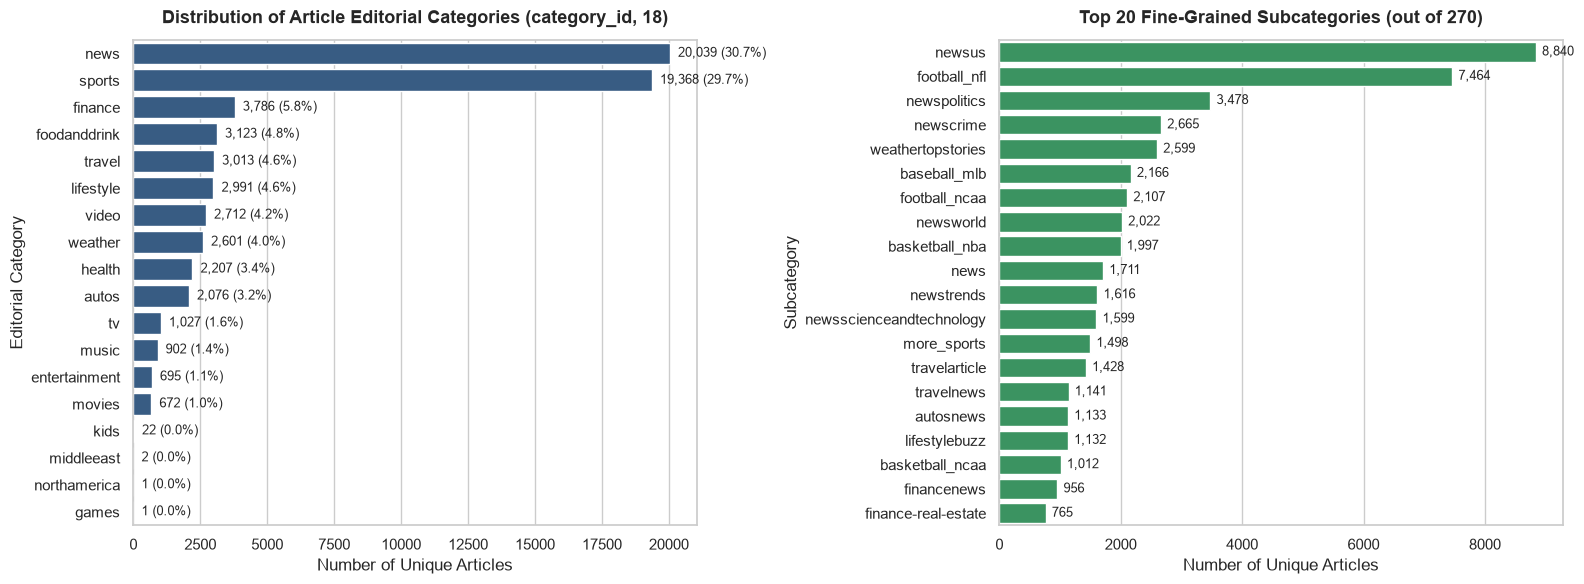

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cat_counts = news["category"].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, ax=axes[0], color="#2b5c8f")
axes[0].set_title(
    "Distribution of Article Editorial Categories (category_id, 18)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[0].set_xlabel("Number of Unique Articles")
axes[0].set_ylabel("Editorial Category")

for i, v in enumerate(cat_counts.values):
    pct = (v / len(news)) * 100
    axes[0].text(v + 300, i, f"{v:,} ({pct:.1f}%)", va="center", fontsize=9.5)

subcat_counts = news["subcategory"].value_counts().head(20)
sns.barplot(x=subcat_counts.values, y=subcat_counts.index, ax=axes[1], color="#2ca25f")
axes[1].set_title(
    "Top 20 Fine-Grained Subcategories (out of 270)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[1].set_xlabel("Number of Unique Articles")
axes[1].set_ylabel("Subcategory")

for i, v in enumerate(subcat_counts.values):
    axes[1].text(v + 100, i, f"{v:,}", va="center", fontsize=9.5)

plt.tight_layout()
plt.show()


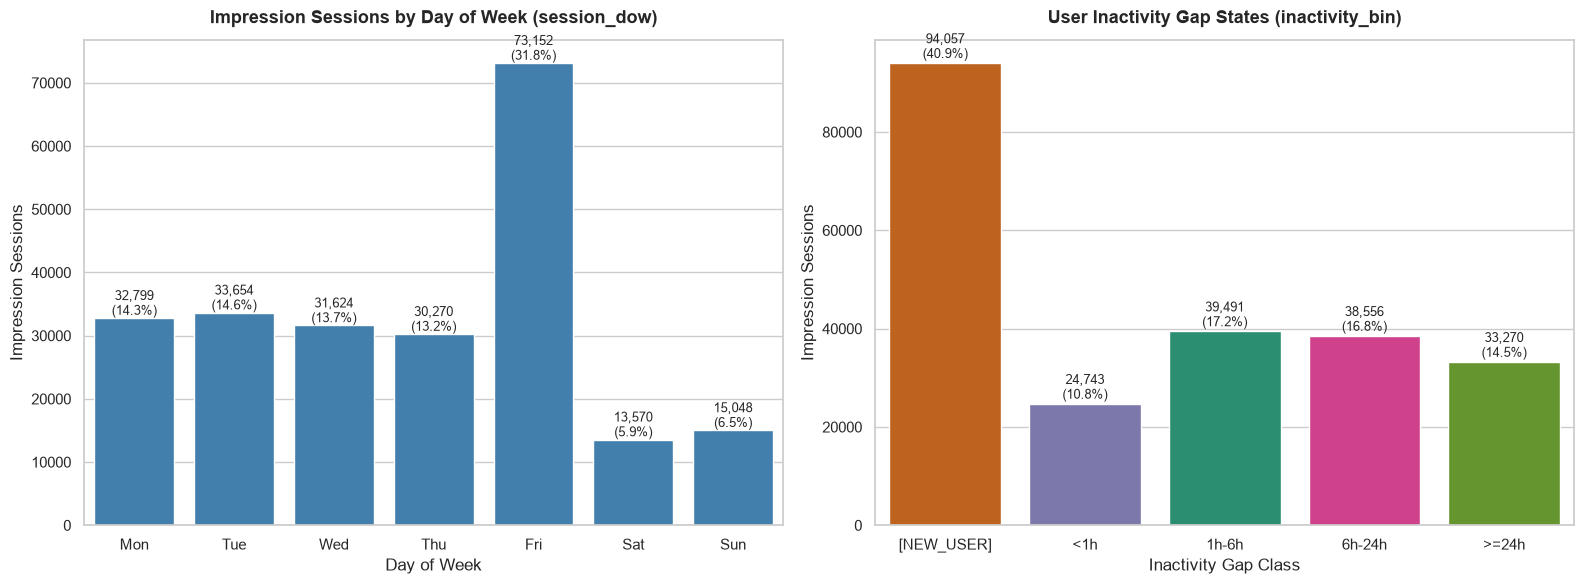

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
dow_map = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}
dow_counts = beh["session_dow"].value_counts().sort_index()
dow_names = [dow_map[i] for i in dow_counts.index]
sns.barplot(x=dow_names, y=dow_counts.values, ax=axes[0], color="#3182bd")
axes[0].set_title(
    "Impression Sessions by Day of Week (session_dow)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[0].set_xlabel("Day of Week")
axes[0].set_ylabel("Impression Sessions")

for i, v in enumerate(dow_counts.values):
    pct = (v / len(beh)) * 100
    axes[0].text(i, v + 500, f"{v:,}\n({pct:.1f}%)", ha="center", fontsize=9.5)

bin_order = ["[NEW_USER]", "<1h", "1h-6h", "6h-24h", ">=24h"]
inact_counts = beh["inactivity_bin"].value_counts().reindex(bin_order)
colors = ["#d95f02", "#7570b3", "#1b9e77", "#e7298a", "#66a61e"]
sns.barplot(x=inact_counts.index, y=inact_counts.values, ax=axes[1], palette=colors)
axes[1].set_title(
    "User Inactivity Gap States (inactivity_bin)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[1].set_xlabel("Inactivity Gap Class")
axes[1].set_ylabel("Impression Sessions")

for i, v in enumerate(inact_counts.values):
    pct = (v / len(beh)) * 100
    axes[1].text(i, v + 1000, f"{v:,}\n({pct:.1f}%)", ha="center", fontsize=9.5)

plt.tight_layout()
plt.show()


## 11. Descriptive tables


In [35]:
news.select_dtypes(include="number").describe().T.to_csv(
    TABLE_DIR / "news_numeric_summary.csv"
)
beh[["history_length", "inactivity_gap", "hour_sin", "hour_cos"]].describe().T.to_csv(
    TABLE_DIR / "behavior_numeric_summary.csv"
)
display(news.select_dtypes(include="number").describe().T)


,count,mean,std,min,25%,50%,75%,max
category_id,65238.0,10.457847,4.328069,0.0,10.0,11.0,13.0,17.0
subcategory_id,65238.0,149.682762,68.057058,0.0,99.0,174.0,192.0,269.0
title_word_count,65238.0,10.736488,3.241998,1.0,9.0,10.0,13.0,48.0
title_char_length,65238.0,66.275453,19.105746,11.0,54.0,64.0,78.0,251.0
title_kg_count,65238.0,1.180830,0.974322,0.0,0.0,1.0,2.0,8.0
abs_kg_count,65238.0,1.894862,1.838848,0.0,0.0,1.0,3.0,30.0
total_kg_count,65238.0,3.075692,2.350414,0.0,1.0,3.0,4.0,32.0


## 12. Feature distributions

Measure category matching over all logged candidate exposures and history availability at user and impression level.


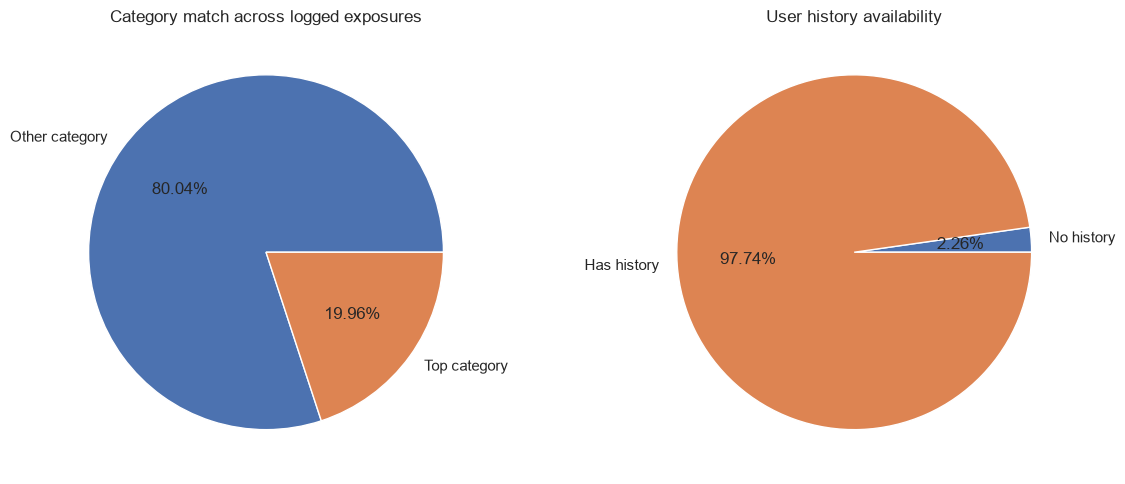

In [36]:
candidate_category = exposures["news_id"].map(news.set_index("news_id")["category"])
impression_history = beh.set_index("impression_id")["history"]
category_lookup = news.set_index("news_id")["category"].to_dict()


def dominant_category(history):
    values = [category_lookup[nid] for nid in history.split() if nid in category_lookup]
    return Counter(values).most_common(1)[0][0] if values else None


top_category = impression_history.map(dominant_category)
observed_match = candidate_category.eq(exposures["impression_id"].map(top_category))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].pie(
    observed_match.value_counts().reindex([False, True], fill_value=0),
    labels=["Other category", "Top category"],
    autopct="%1.2f%%",
)
user_history = descriptors["unique_users"]["history_length"]
axes[1].pie(
    (user_history > 0).value_counts().reindex([False, True], fill_value=0),
    labels=["No history", "Has history"],
    autopct="%1.2f%%",
)
axes[0].set_title("Category match across logged exposures")
axes[1].set_title("User history availability")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "category_match_has_history.png")
plt.show()


## 13. Numeric, categorical and corpus statistics


In [37]:
def numeric_row(name, values, missing=None):
    values = pd.Series(values)
    valid = values.dropna()
    return {
        "feature": name,
        "count": len(valid),
        "mean": valid.mean(),
        "std": valid.std(),
        "min": valid.min(),
        "q1": valid.quantile(0.25),
        "median": valid.median(),
        "q3": valid.quantile(0.75),
        "max": valid.max(),
        "missing": int(values.isna().sum() if missing is None else missing),
    }


numeric_rows = [
    numeric_row("slate_length", slate_summary["slate_length"]),
    numeric_row("history_length_user", user_history),
    numeric_row("history_length_impression", beh["history_length"]),
    numeric_row("historical_ctr_descriptive", descriptors["cand_ctrs"]),
    numeric_row("article_recency_observed", descriptors["recency_series"]),
    numeric_row("inactivity_gap", beh["inactivity_gap"]),
    numeric_row(
        "reading_entropy_user",
        descriptors["entropy_series"],
        len(user_history) - len(descriptors["entropy_series"]),
    ),
]
numeric_table = pd.DataFrame(numeric_rows)
display(numeric_table)
numeric_table.to_csv(TABLE_DIR / "table5_numeric_statistics.csv", index=False)
categorical = []

for name, values in {
    "category_id": news["category_id"],
    "subcategory_id": news["subcategory_id"],
    "session_hour": beh["session_hour"],
    "session_dow": beh["session_dow"],
    "inactivity_bin": beh["inactivity_bin"],
    "category_match": observed_match,
    "has_history": beh["has_history"],
}.items():
    categorical.append(
        {
            "feature": name,
            "cardinality": values.nunique(),
            "missing": values.isna().sum(),
        }
    )
    values.value_counts(dropna=False).to_csv(TABLE_DIR / f"frequency_{name}.csv")

pd.DataFrame(categorical).to_csv(
    TABLE_DIR / "table6_categorical_statistics.csv", index=False
)
corpus_rows = []

for name, values in {"title": news["title"], "abstract": news["abstract"]}.items():
    valid = values.dropna()
    for unit, counts in [
        ("words", valid.str.split().str.len()),
        ("characters", valid.str.len()),
    ]:
        row = numeric_row(f"{name}_{unit}", counts, values.isna().sum())
        row["tokens"] = int(valid.str.split().str.len().sum())
        row["vocabulary"] = len(
            set(word for sentence in valid for word in sentence.split())
        )
        corpus_rows.append(row)


,feature,count,mean,std,min,q1,median,q3,max,missing
0,slate_length,230117,37.304684,38.897923,2.0,10.000000,24.000000,51.000000,299.000000,0
1,history_length_user,94057,21.663778,27.783628,0.0,6.000000,12.000000,26.000000,558.000000,0
2,history_length_impression,230117,32.462413,39.906675,0.0,8.000000,19.000000,42.000000,558.000000,0
3,historical_ctr_descriptive,22771,0.043181,0.116515,0.0,0.000000,0.000000,0.035626,1.000000,0
4,article_recency_observed,200000,24.618332,26.573533,0.0,10.558889,16.242639,25.580625,167.510833,0
5,inactivity_gap,136060,16.703382,21.035304,0.0,1.665833,7.240000,23.857569,165.275833,94057
6,reading_entropy_user,91935,1.428492,0.512174,-0.0,1.098612,1.504788,1.818483,2.535255,2122


In [38]:
for name in ["title_kg_count", "abs_kg_count", "total_kg_count"]:
    row = numeric_row(name, news[name])
    row["zero_entities"] = int(news[name].eq(0).sum())
    corpus_rows.append(row)

pd.DataFrame(corpus_rows).to_csv(
    TABLE_DIR / "table7_text_kg_statistics.csv", index=False
)
split_rows = []

for split, group in beh.groupby("split"):
    candidates = exposures[exposures["impression_id"].isin(group["impression_id"])]
    split_rows.append(
        {
            "split": split,
            "impressions": len(group),
            "users": group.user_id.nunique(),
            "exposed_articles": candidates.news_id.nunique(),
            "ctr": candidates.label.mean(),
            "mean_slate_length": len(candidates) / len(group),
        }
    )

pd.DataFrame(split_rows).to_csv(TABLE_DIR / "split_comparison.csv", index=False)


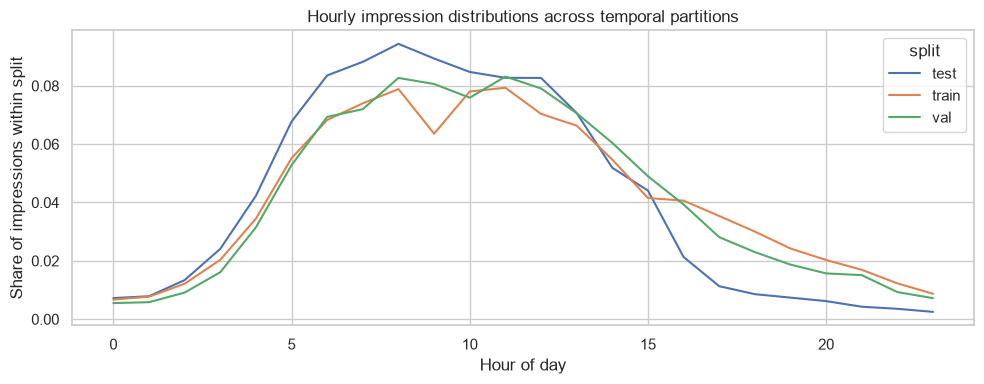

In [39]:
split_hour = (
    beh.assign(session_hour=beh["time"].dt.hour)
    .groupby(["split", "session_hour"])
    .size()
    .unstack(0)
    .fillna(0)
)
(split_hour / split_hour.sum()).plot(figsize=(10, 4))
plt.xlabel("Hour of day")
plt.ylabel("Share of impressions within split")
plt.title("Hourly impression distributions across temporal partitions")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "hourly_distribution_by_split.png")
plt.show()
text_values = pd.concat([news["title"], news["abstract"]]).dropna()
combined = {
    "feature": "combined_text",
    "tokens": sum(len(value.split()) for value in text_values),
    "vocabulary": len(set(word for value in text_values for word in value.split())),
}
corpus_table = pd.read_csv(TABLE_DIR / "table7_text_kg_statistics.csv")
pd.concat([corpus_table, pd.DataFrame([combined])], ignore_index=True).to_csv(
    TABLE_DIR / "table7_text_kg_statistics.csv", index=False
)
